# Within-dataset EU blind spots: MNIST, EMNIST, Fashion-MNIST, BloodMNIST

A standalone adaptation of `eu_blindspot.ipynb`. Each dataset gets **its own model and its own class split**. No dataset serves as the unknown class for another.

- **KKC (known-known):** normal supervised classes, mapped to outputs `0,…,K−1`.
- **KUC (known-unknown):** exposed classes mapped to one learned unknown output `K`.
- **UUC (unknown-unknown):** classes withheld from both encoder and head training. Validation UUC and test UUC are different classes.

We reproduce the core K+1/dropout experiment, followed by confidence quadrants, entropy/margin baselines, bounded feature attacks, exact linear-boundary diagnostics, and training-duration checks. Bootstrap-ensemble comparison is optional. This adapts the original idea to image datasets; it is not a numerical reproduction of its CLIP/CIFAR features.

**Run:** select the `reach-aistats` Python environment and execute cells in order. Everything uses local caches, CPU, and fresh per-dataset encoders. Outputs are deliberately empty so you can inspect each stage. Default caps make this a pilot; increase caps/epochs and repeat seeds before generalizing.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_auc_score, roc_curve
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'eu_blindspot.ipynb').exists():
    ROOT = ROOT / 'Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS'
assert (ROOT / 'eu_blindspot.ipynb').exists(), 'Start in REACH_AISTATS or the repository root'
CACHE = ROOT / 'cache/mnist_reach'
DATASETS = ['mnist', 'emnist', 'fashion', 'blood']
SEED = 0
# Counts: KKC, KUC, validation-only UUC, test-only UUC.
CLASS_COUNTS = {'mnist': (4, 1, 1, 4), 'emnist': (13, 3, 3, 7),
                'fashion': (4, 1, 1, 4), 'blood': (3, 1, 1, 3)}
TRAIN_PER_CLASS = 400
VAL_PER_CLASS = 100
TEST_PER_CLASS = 200  # use None for all available rows in each eligible class
ENCODER_EPOCHS = 5
HEAD_EPOCHS = 100
MC_PASSES = 30
BATCH_SIZE = 256
BOOTSTRAP_DRAWS = 200
ATTACK_ROWS = 128
RUN_BOOTSTRAP_ENSEMBLE = False  # extra independent head fits, frozen encoder
ENSEMBLE_MEMBERS = 5

torch.set_num_threads(4)
torch.manual_seed(SEED)
print('PyTorch', torch.__version__, '| CPU | seed', SEED)

PyTorch 2.14.1+cu130 | CPU | seed 0


## 1. Load and inspect images

MNIST and EMNIST use their official train/test caches; EMNIST letters are transposed to fix orientation and use cached zero-based labels. BloodMNIST uses official train/validation/test splits, converted from RGB to grayscale using Pillow, matching the earlier experiment.

**Fashion cache limitation:** only the official test pool is locally cached. For this exploratory experiment we partition that pool into disjoint stratified 60%/20%/20% train/validation/test subsets. The resulting Fashion evaluation is **not** an official benchmark test score. No download or external pretrained model is required. All encoder inputs are grayscale `[0,1]`.

,dataset,split,source,rows,classes
0,mnist,train,official_train,47995,10
1,mnist,val,official_train,12005,10
2,mnist,test,official_test,10000,10
3,emnist,train,official_train,99840,26
4,emnist,val,official_train,24960,26
5,emnist,test,official_test,20800,26
6,fashion,train,official_test_repartitioned,6000,10
7,fashion,val,official_test_repartitioned,2000,10
8,fashion,test,official_test_repartitioned,2000,10
9,blood,train,official_train,11959,8


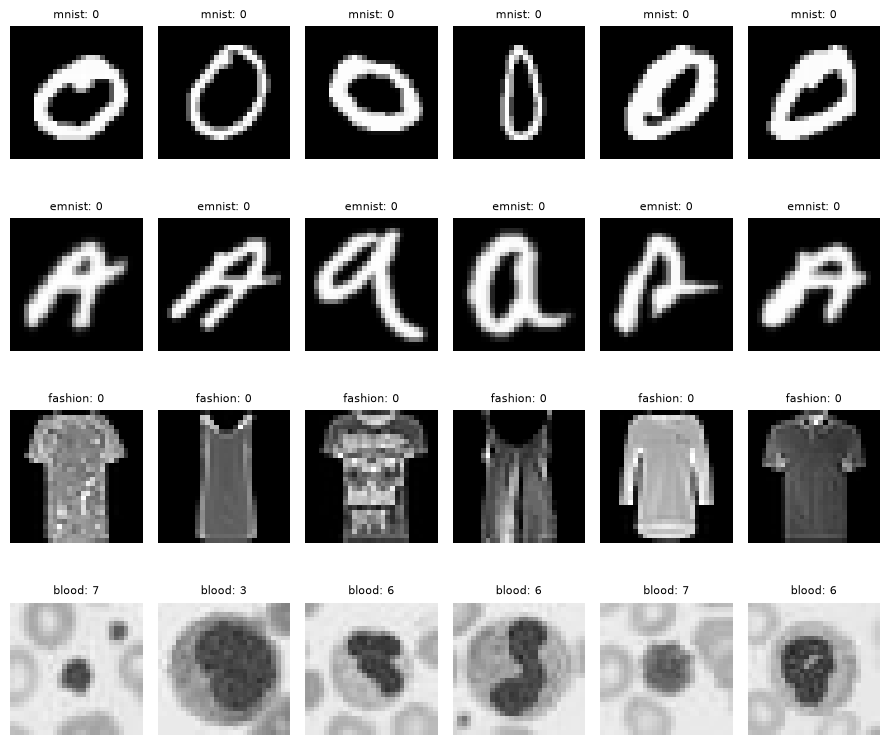

In [2]:
def read_npz(name, split, transpose=False):
    path = CACHE / f'{name}_{split}.npz'
    with np.load(path, allow_pickle=False) as data:
        x, y = data['X'].copy(), data['y'].astype(np.int64).reshape(-1)
    if transpose:
        x = x.transpose(0, 2, 1)
    return np.ascontiguousarray(x), y

def partition_indices(y, fractions, seed):
    rng = np.random.default_rng(seed)
    parts = [[] for _ in fractions]
    for c in np.unique(y):
        ids = rng.permutation(np.flatnonzero(y == c))
        bounds = np.r_[0, (np.cumsum(fractions)[:-1]*len(ids)).astype(int), len(ids)]
        for j in range(len(parts)):
            parts[j].extend(ids[bounds[j]:bounds[j+1]])
    return [np.asarray(p, dtype=np.int64) for p in parts]

def entry(x, y, ids, source):
    return dict(images=x[ids], labels=y[ids], source_index=ids, source=source)

raw = {}
for name in DATASETS:
    if name in ('mnist', 'emnist'):
        cache_name = 'letters' if name == 'emnist' else name
        x, y = read_npz(cache_name, 'train', transpose=name == 'emnist')
        tr, va = partition_indices(y, [.8, .2], SEED + 1)
        raw[name] = {'train': entry(x, y, tr, 'official_train'),
                     'val': entry(x, y, va, 'official_train')}
        x, y = read_npz(cache_name, 'test', transpose=name == 'emnist')
        raw[name]['test'] = entry(x, y, np.arange(len(y)), 'official_test')
    elif name == 'fashion':
        x, y = read_npz('fashion', 'test')
        ids = partition_indices(y, [.6, .2, .2], SEED + 1)
        raw[name] = {split: entry(x, y, ix, 'official_test_repartitioned')
                     for split, ix in zip(['train', 'val', 'test'], ids)}
    elif name == 'blood':
        raw[name] = {}
        with np.load(CACHE / 'bloodmnist_original.npz', allow_pickle=False) as data:
            for split in ['train', 'val', 'test']:
                x = np.stack([np.asarray(Image.fromarray(im).convert('L'))
                              for im in data[f'{split}_images']])
                y = data[f'{split}_labels'].astype(np.int64).reshape(-1)
                raw[name][split] = entry(x, y, np.arange(len(y)), 'official_' + split)
    for pool in raw[name].values():
        assert pool['images'].shape == (len(pool['labels']), 28, 28)
        assert pool['images'].dtype == np.uint8

display(pd.DataFrame([dict(dataset=name, split=split, source=p['source'],
                           rows=len(p['labels']), classes=len(np.unique(p['labels'])))
                      for name, splits in raw.items() for split, p in splits.items()]))
fig, axes = plt.subplots(len(DATASETS), 6, figsize=(9, 2*len(DATASETS)), squeeze=False)
for row, name in enumerate(DATASETS):
    p = raw[name]['train']
    for j, ax in enumerate(axes[row]):
        ax.imshow(p['images'][j], cmap='gray', vmin=0, vmax=255)
        ax.set_title(f"{name}: {p['labels'][j]}", fontsize=8)
        ax.axis('off')
plt.tight_layout()
plt.show()

## 2. Assign disjoint class roles and image pools

A seeded class permutation assigns the requested counts. Each class has exactly one role. Training uses KKC and KUC only; validation uses KKC/KUC plus validation-only UUC; test uses KKC/KUC plus test-only UUC. Validation UUC is reserved for inspection, and does not set thresholds or enter fitting. Calibration uses **only validation KKC**.

Caps are per original class, with sampling without replacement. This changes class prevalence; rates describe these sampled pools. `assignments` records source split, original row index, class, role, and experimental split. Assertions check both row and class separation.

In [3]:
worlds, assignment_rows, class_rows = {}, [], []
for number, name in enumerate(DATASETS):
    rng = np.random.default_rng(SEED + 10*number)
    classes = np.unique(raw[name]['train']['labels'])
    counts = CLASS_COUNTS[name]
    assert sum(counts) == len(classes) and counts[0] >= 2 and min(counts) >= 1
    order = rng.permutation(classes)
    groups = dict(zip(['kkc', 'kuc', 'uuc_val', 'uuc_test'], np.split(order, np.cumsum(counts)[:-1])))
    world = dict(groups=groups, K=len(groups['kkc']), seed=SEED + 10*number)
    for role, labels in groups.items():
        for label in labels:
            class_rows.append(dict(dataset=name, label=int(label), role=role))
    for split, cap in [('train', TRAIN_PER_CLASS), ('val', VAL_PER_CLASS), ('test', TEST_PER_CLASS)]:
        allowed_roles = ['kkc', 'kuc'] + ([] if split == 'train' else ['uuc_' + split])
        pool = raw[name][split]
        selected, role_list = [], []
        for role in allowed_roles:
            for c in groups[role]:
                ids = rng.permutation(np.flatnonzero(pool['labels'] == c))
                ids = ids if cap is None else ids[:cap]
                assert len(ids), (name, split, c)
                selected.extend(ids)
                role_list.extend([role]*len(ids))
        ids = np.asarray(selected, dtype=np.int64)
        world[split] = dict(images=pool['images'][ids], labels=pool['labels'][ids],
                            roles=np.asarray(role_list), source_index=pool['source_index'][ids])
        for i, role in zip(ids, role_list):
            assignment_rows.append(dict(dataset=name, split=split, source=pool['source'],
                                        index=int(pool['source_index'][i]), label=int(pool['labels'][i]), role=role))
    assert set(world['train']['labels']).isdisjoint(set(groups['uuc_val']) | set(groups['uuc_test']))
    assert set(groups['uuc_val']).isdisjoint(groups['uuc_test'])
    world['label_map'] = {int(c): j for j, c in enumerate(groups['kkc'])}
    worlds[name] = world
assignments = pd.DataFrame(assignment_rows)
assert not assignments.duplicated(['dataset', 'source', 'index']).any(), 'Image leakage'
class_roles = pd.DataFrame(class_rows)
display(class_roles.groupby(['dataset', 'role']).label.apply(list).to_frame())
display(assignments.groupby(['dataset', 'split', 'role']).size().rename('rows').to_frame())

label
dataset role                                                    
blood   kkc                                            [1, 6, 0]
        kuc                                                  [5]
        uuc_test                                       [7, 3, 2]
        uuc_val                                              [4]
emnist  kkc       [7, 9, 11, 5, 17, 25, 19, 6, 1, 4, 15, 18, 10]
        kuc                                          [23, 14, 3]
        uuc_test                      [20, 8, 21, 22, 0, 13, 24]
        uuc_val                                      [16, 2, 12]
fashion kkc                                         [8, 7, 4, 0]
        kuc                                                  [6]
        uuc_test                                    [3, 2, 1, 5]
        uuc_val                                              [9]
mnist   kkc                                         [4, 6, 2, 7]
        kuc                                                  [3]
        uuc_test                                    [9, 0, 8, 1]
        uuc_val                                              [5]

rows
dataset split role          
blood   test  kkc        600
              kuc        200
              uuc_test   600
        train kkc       1200
              kuc        400
        val   kkc        300
              kuc        100
              uuc_val    100
emnist  test  kkc       2600
              kuc        600
              uuc_test  1400
        train kkc       5200
              kuc       1200
        val   kkc       1300
              kuc        300
              uuc_val    300
fashion test  kkc        800
              kuc        200
              uuc_test   800
        train kkc       1600
              kuc        400
        val   kkc        400
              kuc        100
              uuc_val    100
mnist   test  kkc        800
              kuc        200
              uuc_test   800
        train kkc       1600
              kuc        400
        val   kkc        400
              kuc        100
              uuc_val    100

## 3. Train a fresh encoder per dataset on KKC images only

The original notebook starts with pretrained CLIP features. Here a small CNN learns 64-dimensional features from that dataset's KKC training images. KUC and UUC do not train the encoder. We then freeze it and normalize feature vectors to unit L2 norm for the head and feature-space diagnostics. Encoder and head may share training images; neither sees validation/test images during fitting.

The encoder is part of the experiment: poor known-class generalization limits interpretation of uncertainty. Training history and later KKC validation/test accuracy are essential checks. No saved all-class MNIST checkpoint is reused.

In [4]:
class ImageEncoder(nn.Module):
    def __init__(self, k):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                  nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten())
        self.emb = nn.Sequential(nn.Linear(32*7*7, 64), nn.ReLU())
        self.output = nn.Linear(64, k)
    def features(self, x):
        return self.emb(self.conv(x))
    def forward(self, x):
        return self.output(self.features(x))

def mapped_labels(world, labels):
    return torch.tensor([world['label_map'].get(int(c), world['K']) for c in labels], dtype=torch.long)

def fit(model, x, y, epochs, seed, batch_size=BATCH_SIZE):
    torch.manual_seed(seed)
    loader = DataLoader(TensorDataset(x, y), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    losses = []
    for epoch in range(epochs):
        model.train()
        total = 0.
        for xb, yb in loader:
            opt.zero_grad()
            loss = nn.functional.cross_entropy(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item()*len(yb)
        losses.append(total/len(y))
    model.eval()
    return losses

def image_tensor(x):
    return torch.from_numpy(np.ascontiguousarray(x)).float()[:, None]/255.

for name, w in worlds.items():
    torch.manual_seed(w['seed'])
    encoder = ImageEncoder(w['K'])
    keep = w['train']['roles'] == 'kkc'
    x = image_tensor(w['train']['images'][keep])
    y = mapped_labels(w, w['train']['labels'][keep])
    w['encoder_losses'] = fit(encoder, x, y, ENCODER_EPOCHS, w['seed'])
    encoder.requires_grad_(False).eval()
    w['encoder'] = encoder
    for split in ['train', 'val', 'test']:
        chunks = []
        images = w[split]['images']
        with torch.no_grad():
            for start in range(0, len(images), BATCH_SIZE):
                f = encoder.features(image_tensor(images[start:start+BATCH_SIZE]))
                chunks.append(nn.functional.normalize(f, dim=1))
        w[split]['X'] = torch.cat(chunks)
        assert torch.isfinite(w[split]['X']).all()
    print(name, 'encoder loss:', [round(v, 4) for v in w['encoder_losses']])

mnist encoder loss: [1.3477, 1.156, 0.8099, 0.4473, 0.2534]
emnist encoder loss: [2.3489, 1.3986, 0.9567, 0.7977, 0.6965]
fashion encoder loss: [1.3419, 1.0618, 0.607, 0.3164, 0.2017]
blood encoder loss: [1.1029, 1.0768, 1.0503, 1.0073, 0.9543]


## 4. Train the K+1 dropout heads

Same head family as the original: Linear(64,128) → ReLU → Dropout(0.5) → Linear(128,K+1), Adam at 0.001. All KUC classes share output K. The pilot uses 100 epochs; set `HEAD_EPOCHS=300` for the original duration. Class counts and sampling caps determine the exposure weight; no additional class weighting is applied.

mnist training accuracy: 0.875
emnist training accuracy: 0.7717
fashion training accuracy: 0.787
blood training accuracy: 0.6769


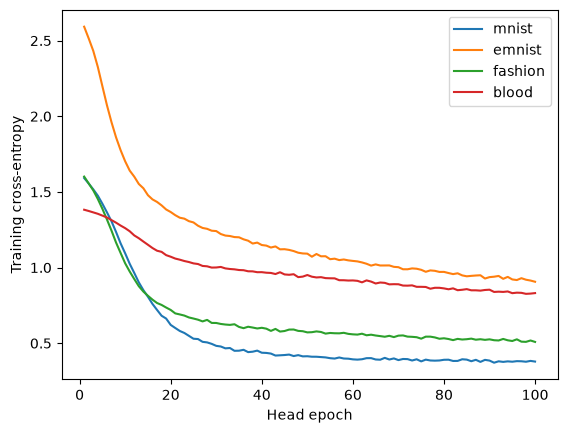

In [5]:
class HeadDrop(nn.Module):
    def __init__(self, k):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Dropout(.5), nn.Linear(128, k+1))
    def forward(self, x):
        return self.net(x)

for name, w in worlds.items():
    torch.manual_seed(w['seed'] + 100)
    head = HeadDrop(w['K'])
    w['train_y'] = mapped_labels(w, w['train']['labels'])
    w['head_losses'] = fit(head, w['train']['X'], w['train_y'], HEAD_EPOCHS, w['seed'] + 100)
    w['head'] = head
    with torch.no_grad():
        acc = (head(w['train']['X']).argmax(1) == w['train_y']).float().mean().item()
    print(name, 'training accuracy:', round(acc, 4))
    plt.plot(np.arange(1, HEAD_EPOCHS+1), w['head_losses'], label=name)
plt.xlabel('Head epoch'); plt.ylabel('Training cross-entropy'); plt.legend()
plt.show()

## 5. MC-dropout decomposition and validation-only cutoffs

For T stochastic passes, TU is entropy of the mean probabilities, AU is mean pass entropy, and EU/BALD is TU−AU (all K+1 outputs, natural logarithms). Dropout alone is activated for sampling, and module modes are restored afterwards.

The confidence and EU cutoffs are the 90th percentiles of **validation KKC**. Test data never determines them. KUC and validation UUC are excluded from calibration. Mean-probability predictions and all-output margin/MSP provide comparison scores.

In [6]:
def mc_probs(model, x, passes=MC_PASSES):
    modes = {module: module.training for module in model.modules()}
    try:
        model.eval()
        for module in model.modules():
            if isinstance(module, nn.Dropout):
                module.train()
        with torch.no_grad():
            return torch.stack([model(x).softmax(-1) for _ in range(passes)]).numpy()
    finally:
        for module, mode in modes.items():
            module.training = mode

def decompose(p):
    p = p.astype(np.float64)
    entropy = lambda a: -(a*np.log(np.clip(a, 1e-12, None))).sum(-1)
    tu, au = entropy(p.mean(0)), entropy(p).mean(0)
    return tu, au, tu-au

def score(model, x, k, seed):
    torch.manual_seed(seed)
    chunks = []
    model.eval()
    for start in range(0, len(x), BATCH_SIZE):
        xb = x[start:start+BATCH_SIZE]
        p = mc_probs(model, xb)
        tu, au, eu = decompose(p)
        with torch.no_grad():
            z = model(xb).numpy()
        ordered = np.sort(z, axis=1)
        known_ordered = np.sort(z[:, :k], axis=1)
        chunks.append(pd.DataFrame(dict(tu=tu, au=au, eu=eu, p_unknown=p.mean(0)[:, k],
            prediction=p.mean(0).argmax(1), neg_margin=-(ordered[:, -1]-ordered[:, -2]),
            neg_msp=-torch.from_numpy(z).softmax(-1).numpy().max(1),
            neg_known_margin=-(known_ordered[:, -1]-known_ordered[:, -2]))))
    out = pd.concat(chunks, ignore_index=True)
    assert np.isfinite(out.to_numpy()).all() and out.eu.min() > -1e-8
    return out

calibration_rows = []
for name, w in worlds.items():
    keep = w['val']['roles'] == 'kkc'
    cal = score(w['head'], w['val']['X'][keep], w['K'], w['seed'] + 200)
    w['q_tu'], w['q_eu'] = cal.tu.quantile(.9), cal.eu.quantile(.9)
    calibration_rows.append(dict(dataset=name, n=len(cal), q_tu=w['q_tu'], q_eu=w['q_eu'],
        known_accuracy=(cal.prediction.to_numpy() == mapped_labels(w, w['val']['labels'][keep]).numpy()).mean()))
calibration = pd.DataFrame(calibration_rows)
display(calibration.round(4))

,dataset,n,q_tu,q_eu,known_accuracy
0,mnist,400,0.7906,0.0757,0.8850
1,emnist,1300,1.7179,0.2549,0.7723
2,fashion,400,0.9959,0.0555,0.8950
3,blood,300,1.2314,0.0377,0.8200


## 6. Test readout by class role

**Warning:** TU ≤ validation TU q90 and EU > validation EU q90. **Low-TU/low-EU:** both below their cutoffs. Neither quadrant has a predetermined 10% rate.

For UUC, the key missed-warning subset also predicts a **known** output. A low-entropy unknown-output prediction is successful rejection, not a confident known-class error. KKC accuracy counts unknown predictions as wrong. KUC/UUC task accuracy means unknown rejection, not subclass classification.

In [7]:
test_frames = []
for name, w in worlds.items():
    out = score(w['head'], w['test']['X'], w['K'], w['seed'] + 300)
    out['dataset'] = name
    out['label'] = w['test']['labels']
    out['role'] = w['test']['roles']
    out['source_index'] = w['test']['source_index']
    out['test_position'] = np.arange(len(out))
    out['warning'] = (out.tu <= w['q_tu']) & (out.eu > w['q_eu'])
    out['low_tu_low_eu'] = (out.tu <= w['q_tu']) & (out.eu <= w['q_eu'])
    out['predicted_known'] = out.prediction < w['K']
    out['low_tu_low_eu_known'] = out.low_tu_low_eu & out.predicted_known
    out['task_correct'] = out.prediction.to_numpy() == mapped_labels(w, out.label).numpy()
    w['test_scores'] = out
    test_frames.append(out)
results = pd.concat(test_frames, ignore_index=True)
summary = results.groupby(['dataset', 'role']).agg(n=('tu', 'size'),
    task_accuracy=('task_correct', 'mean'), TU=('tu', 'mean'), AU=('au', 'mean'), EU=('eu', 'mean'),
    P_unknown=('p_unknown', 'mean'), warning_rate=('warning', 'mean'),
    low_TU_low_EU_rate=('low_tu_low_eu', 'mean'),
    low_TU_low_EU_known_rate=('low_tu_low_eu_known', 'mean'))
display(summary.round(4))
print('For KKC, low-TU/low-EU known predictions can be correct. For UUC, they are missed warnings.')

n  task_accuracy      TU      AU      EU  P_unknown  \
dataset role                                                               
blood   kkc        600         0.8067  0.9147  0.8870  0.0277     0.2192   
        kuc        200         0.4100  1.0657  1.0407  0.0250     0.3455   
        uuc_test   600         0.0883  0.5456  0.5210  0.0246     0.1213   
emnist  kkc       2600         0.7550  1.1877  1.0275  0.1602     0.1149   
        kuc        600         0.7467  1.3341  1.1534  0.1807     0.4933   
        uuc_test  1400         0.4821  1.3836  1.1986  0.1850     0.3463   
fashion kkc        800         0.8912  0.5271  0.4967  0.0304     0.1662   
        kuc        200         0.2750  0.9045  0.8637  0.0408     0.3587   
        uuc_test   800         0.2138  0.8159  0.7748  0.0411     0.2821   
mnist   kkc        800         0.8900  0.4219  0.3807  0.0412     0.0976   
        kuc        200         0.7750  0.7300  0.6751  0.0549     0.6348   
        uuc_test   800         0.6000  0.8383  0.7674  0.0709     0.4595   

                  warning_rate  low_TU_low_EU_rate  low_TU_low_EU_known_rate  
dataset role                                                                  
blood   kkc             0.0850              0.8367                    0.7333  
        kuc             0.0350              0.9000                    0.5050  
        uuc_test        0.0767              0.8550                    0.7683  
emnist  kkc             0.0596              0.8423                    0.7896  
        kuc             0.0367              0.8500                    0.1933  
        uuc_test        0.0507              0.7100                    0.3350  
fashion kkc             0.0425              0.8262                    0.8238  
        kuc             0.0250              0.6050                    0.5950  
        uuc_test        0.0850              0.6125                    0.5962  
mnist   kkc             0.0375              0.8450                    0.8112  
        kuc             0.0450              0.6650                    0.1300  
        uuc_test        0.0388              0.3775                    0.1888

For KKC, low-TU/low-EU known predictions can be correct. For UUC, they are missed warnings.


## 7. Detection against entropy and margin baselines

Compute KKC vs **test UUC**, excluding KUC. Report exposed KUC separately. Scores are oriented so larger means more unknown-like. All-output margins/MSP account for the learned unknown logit; the known-only margin is included for comparison.

AUROC intervals use stratified row bootstrap conditional on this fitted model and class split. They are not uncertainty over training seeds or class choices. EU is exactly TU−AU, so adding dropout EU to a model already given TU and AU adds no independent information. Per-class comparisons always use KKC negatives, never other unknown classes.

,dataset,positives,score,auroc,lo,hi,fpr95
7,mnist,uuc_test,eu,0.8090,0.7868,0.8295,0.5012
8,mnist,uuc_test,tu,0.8618,0.8437,0.8785,0.4200
9,mnist,uuc_test,au,0.8633,0.8462,0.8781,0.4175
10,mnist,uuc_test,p_unknown,0.8461,0.8308,0.8631,0.6575
11,mnist,uuc_test,neg_margin,0.7909,0.7709,0.8126,0.4488
12,mnist,uuc_test,neg_msp,0.8190,0.7985,0.8379,0.4150
13,mnist,uuc_test,neg_known_margin,0.8717,0.8532,0.8895,0.3812
21,emnist,uuc_test,eu,0.6111,0.5953,0.6294,0.8550
22,emnist,uuc_test,tu,0.6390,0.6225,0.6560,0.9146
23,emnist,uuc_test,au,0.6386,0.6207,0.6557,0.9200


,dataset,uuc_class,eu,tu,au,p_unknown,neg_margin,neg_msp,neg_known_margin
0,mnist,9,0.7635,0.7548,0.7512,0.5520,0.7408,0.7465,0.8350
1,mnist,0,0.8045,0.8960,0.9006,0.9375,0.8116,0.8489,0.8812
2,mnist,8,0.8542,0.9180,0.9210,0.9224,0.8392,0.8734,0.8972
3,mnist,1,0.8136,0.8782,0.8806,0.9725,0.7720,0.8071,0.8736
4,emnist,20,0.4608,0.3781,0.3736,0.9726,0.3642,0.3558,0.7036
5,emnist,8,0.4632,0.4195,0.4143,0.3807,0.4202,0.4038,0.4707
6,emnist,21,0.6255,0.7018,0.7086,0.8676,0.6412,0.6617,0.7525
7,emnist,22,0.5645,0.7035,0.7220,0.9057,0.6599,0.6987,0.7713
8,emnist,0,0.6950,0.7619,0.7647,0.8390,0.6900,0.7245,0.6600
9,emnist,13,0.6416,0.6901,0.6921,0.8632,0.6423,0.6663,0.7086


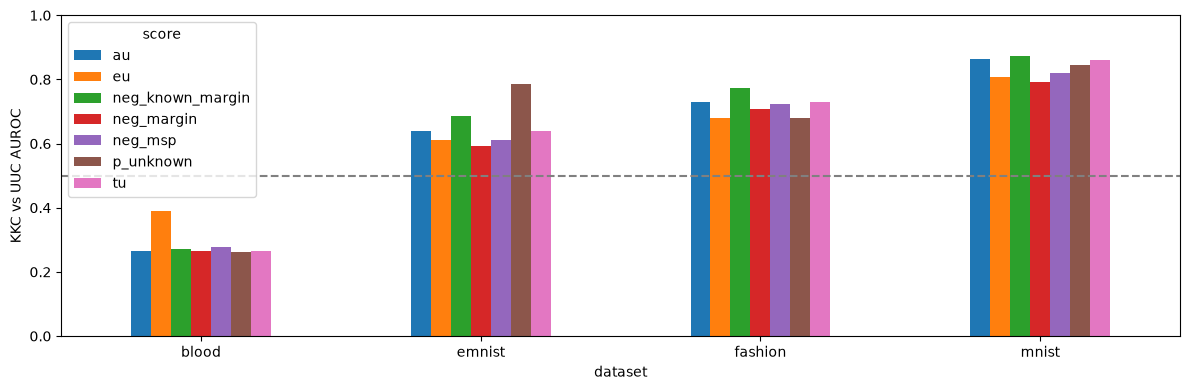

In [8]:
SCORES = ['eu', 'tu', 'au', 'p_unknown', 'neg_margin', 'neg_msp', 'neg_known_margin']
def auc_interval(y, values, seed, draws=BOOTSTRAP_DRAWS):
    rng = np.random.default_rng(seed)
    neg, pos = np.flatnonzero(y == 0), np.flatnonzero(y == 1)
    samples = []
    for _ in range(draws):
        ix = np.r_[rng.choice(neg, len(neg)), rng.choice(pos, len(pos))]
        samples.append(roc_auc_score(y[ix], values[ix]))
    return np.quantile(samples, [.025, .975])

detection_rows, per_class_rows = [], []
for name, w in worlds.items():
    frame = w['test_scores']
    for role in ['kuc', 'uuc_test']:
        sub = frame[frame.role.isin(['kkc', role])]
        y = (sub.role == role).to_numpy().astype(int)
        for s in SCORES:
            values = sub[s].to_numpy()
            fpr, tpr, _ = roc_curve(y, values)
            lo, hi = auc_interval(y, values, w['seed'] + 400)
            detection_rows.append(dict(dataset=name, positives=role, score=s, auroc=roc_auc_score(y, values),
                                       lo=lo, hi=hi, fpr95=fpr[np.flatnonzero(tpr >= .95)[0]]))
    for label in w['groups']['uuc_test']:
        sub = frame[(frame.role == 'kkc') | (frame.label == label)]
        y = (sub.label == label).to_numpy()
        per_class_rows.append(dict(dataset=name, uuc_class=int(label),
                                   **{s: roc_auc_score(y, sub[s]) for s in SCORES}))
detection = pd.DataFrame(detection_rows)
per_class_detection = pd.DataFrame(per_class_rows)
display(detection[detection.positives == 'uuc_test'].round(4))
display(per_class_detection.round(4))
detection[detection.positives == 'uuc_test'].pivot(index='dataset', columns='score', values='auroc').plot.bar(
    figsize=(12, 4), ylim=(0, 1), rot=0, ylabel='KKC vs UUC AUROC')
plt.axhline(.5, color='gray', ls='--'); plt.tight_layout(); plt.show()

## 8. Plot quadrants and inspect missed warnings

Each dataset gets its own validation cutoffs and model. Plot scales are shared to help inspection, but maximum possible entropy varies with K+1. Examples are deliberately selected failure cases; use the table above for prevalence.

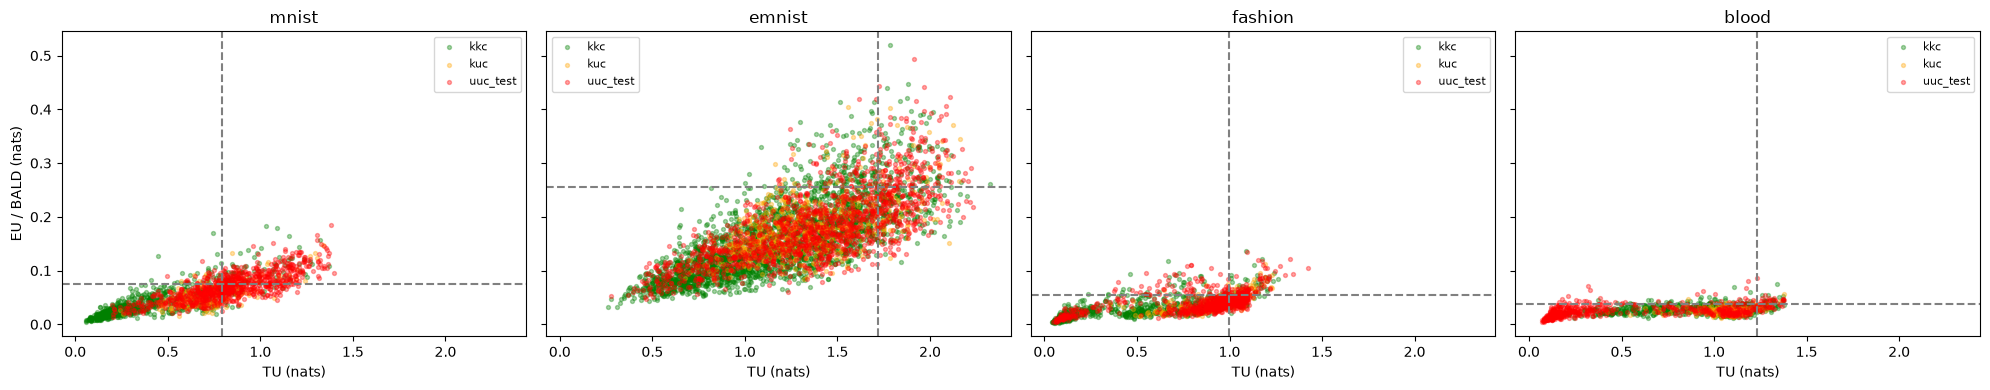

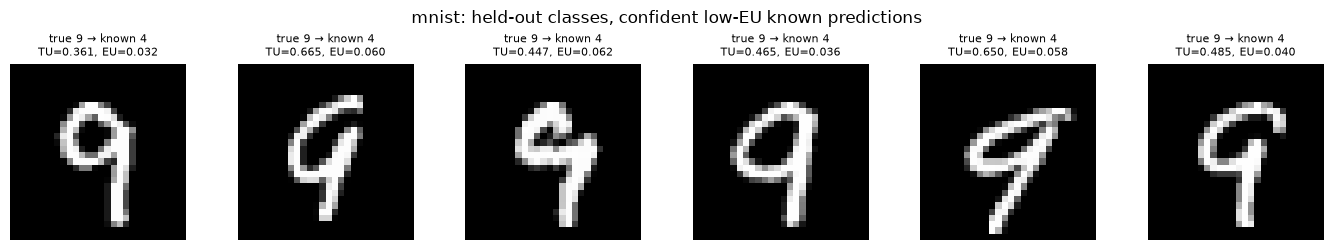

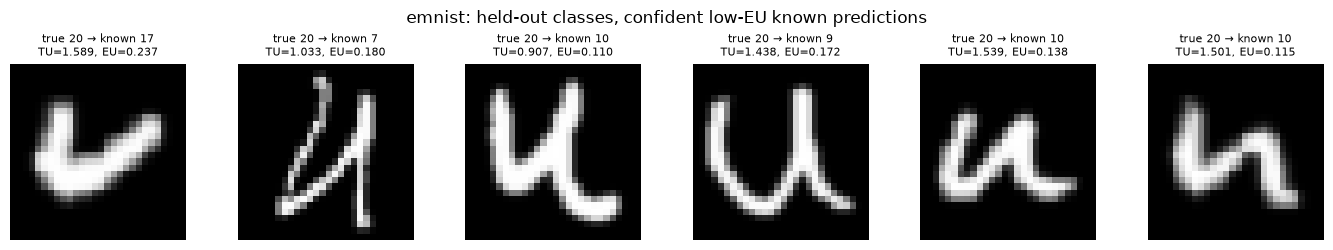

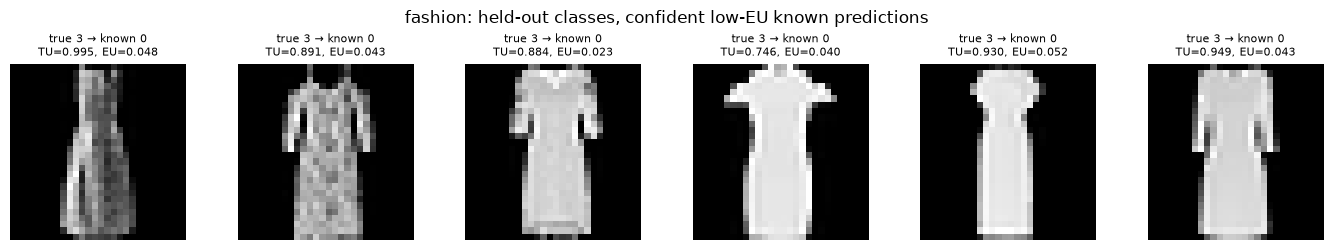

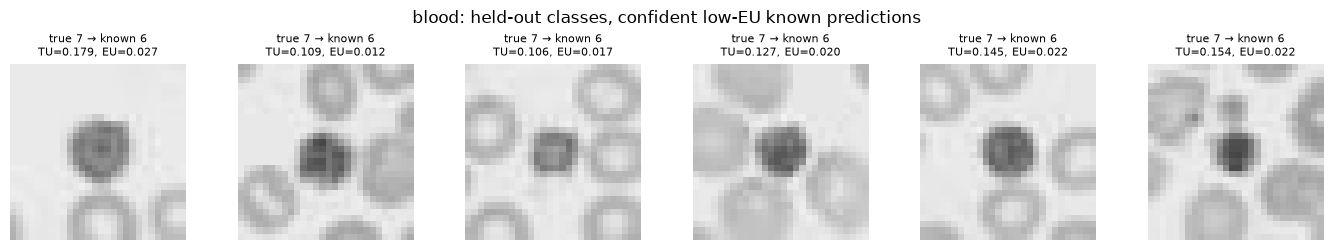

In [9]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5*len(DATASETS), 4), squeeze=False, sharex=True, sharey=True)
for ax, name in zip(axes[0], DATASETS):
    w = worlds[name]
    for role, color in [('kkc', 'green'), ('kuc', 'orange'), ('uuc_test', 'red')]:
        f = w['test_scores'].query('role == @role')
        ax.scatter(f.tu, f.eu, s=8, alpha=.35, color=color, label=role)
    ax.axvline(w['q_tu'], color='gray', ls='--')
    ax.axhline(w['q_eu'], color='gray', ls='--')
    ax.set(title=name, xlabel='TU (nats)')
    ax.legend(fontsize=8)
axes[0, 0].set_ylabel('EU / BALD (nats)')
plt.tight_layout(); plt.show()

for name, w in worlds.items():
    cases = w['test_scores'].query("role == 'uuc_test' and low_tu_low_eu_known").head(6)
    if cases.empty:
        print(name, ': no UUC missed warnings at these cutoffs')
        continue
    fig, axes = plt.subplots(1, len(cases), figsize=(2.3*len(cases), 2.5), squeeze=False)
    for ax, (_, row) in zip(axes[0], cases.iterrows()):
        image = w['test']['images'][int(row.test_position)]
        predicted_class = w['groups']['kkc'][int(row.prediction)]
        ax.imshow(image, cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'true {int(row.label)} → known {predicted_class}\nTU={row.tu:.3f}, EU={row.eu:.3f}', fontsize=8)
        ax.axis('off')
    fig.suptitle(f'{name}: held-out classes, confident low-EU known predictions')
    plt.tight_layout(); plt.show()

## 9. Bounded feature-space attacks and matched random controls

Attack KKC test features using deterministic-head cross-entropy and an L2 ball around each original feature. No sphere projection or image realizability is assumed. Inputs start unit-normalized, but perturbed features need not remain on the sphere. A matched random control has the **same measured displacement per row** as PGD. Report displacement, radial change, angle, accuracy, uncertainty, and fixed-threshold quadrants. These attacks do not correspond to a pixel perturbation budget.

This diagnostic is capped at `ATTACK_ROWS` KKC examples per dataset. Clean-versus-attacked score AUROC measures change, not detection of held-out semantic classes.

In [10]:
def pgd_l2(model, x, y, eps, steps=20):
    model.eval()
    adv = x.clone()
    for _ in range(steps):
        adv = adv.detach().requires_grad_(True)
        loss = nn.functional.cross_entropy(model(adv), y)
        grad, = torch.autograd.grad(loss, adv)
        with torch.no_grad():
            adv = adv + (2*eps/steps)*nn.functional.normalize(grad, dim=1)
            delta = adv-x
            delta *= (eps/delta.norm(dim=1, keepdim=True).clamp_min(1e-12)).clamp(max=1)
            adv = x+delta
    assert (adv-x).norm(dim=1).max() <= eps+1e-5
    return adv.detach()

def geometry(x, adv):
    radial = adv.norm(dim=1)-x.norm(dim=1)
    cos = nn.functional.cosine_similarity(x, adv, dim=1).clamp(-1, 1)
    return float(radial.abs().mean()), float(torch.rad2deg(torch.acos(cos)).mean())

attack_rows = []
for name, w in worlds.items():
    ids = np.flatnonzero(w['test']['roles'] == 'kkc')
    ids = np.random.default_rng(w['seed']).permutation(ids)[:ATTACK_ROWS]
    x = w['test']['X'][ids]
    y = mapped_labels(w, w['test']['labels'][ids])
    clean = score(w['head'], x, w['K'], w['seed']+500)
    generator = torch.Generator().manual_seed(w['seed']+501)
    for eps in [0., .01, .03, .1, .3]:
        attacked = x if eps == 0 else pgd_l2(w['head'], x, y, eps)
        random_direction = nn.functional.normalize(torch.randn(x.shape, generator=generator), dim=1)
        random_x = x+random_direction*(attacked-x).norm(dim=1, keepdim=True)
        for kind, adv in [('pgd', attacked), ('matched_random', random_x)]:
            sc = score(w['head'], adv, w['K'], w['seed']+500)
            radial, angle = geometry(x, adv)
            ybin = np.r_[np.zeros(len(x)), np.ones(len(x))]
            attack_rows.append(dict(dataset=name, kind=kind, eps=eps,
                displacement=float((adv-x).norm(dim=1).mean()), radial=radial, angle_deg=angle,
                accuracy=(sc.prediction.to_numpy() == y.numpy()).mean(), TU=sc.tu.mean(), EU=sc.eu.mean(),
                warning=((sc.tu <= w['q_tu']) & (sc.eu > w['q_eu'])).mean(),
                low_TU_low_EU_wrong=((sc.tu <= w['q_tu']) & (sc.eu <= w['q_eu']) & (sc.prediction != y.numpy())).mean(),
                eu_change_auroc=roc_auc_score(ybin, np.r_[clean.eu, sc.eu])))
attacks = pd.DataFrame(attack_rows)
display(attacks.round(4))

,dataset,kind,eps,displacement,radial,angle_deg,accuracy,TU,EU,warning,low_TU_low_EU_wrong,eu_change_auroc
0,mnist,pgd,0.00,0.00,0.0000,0.0011,0.8750,0.4055,0.0385,0.0469,0.0391,0.5000
1,mnist,matched_random,0.00,0.00,0.0000,0.0011,0.8750,0.4055,0.0385,0.0469,0.0391,0.5000
2,mnist,pgd,0.01,0.01,0.0025,0.5470,0.8672,0.4211,0.0398,0.0312,0.0547,0.5212
3,mnist,matched_random,0.01,0.01,0.0011,0.5676,0.8672,0.4053,0.0385,0.0469,0.0391,0.4996
4,mnist,pgd,0.03,0.03,0.0071,1.6541,0.8438,0.4531,0.0424,0.0312,0.0703,0.5552
5,mnist,matched_random,0.03,0.03,0.0030,1.7048,0.8750,0.4057,0.0386,0.0391,0.0391,0.5031
6,mnist,pgd,0.10,0.10,0.0188,5.6285,0.7422,0.5723,0.0529,0.0625,0.1328,0.6827
7,mnist,matched_random,0.10,0.10,0.0098,5.6705,0.8672,0.4042,0.0385,0.0234,0.0547,0.4990
8,mnist,pgd,0.30,0.30,0.0344,17.2235,0.1641,0.6845,0.0612,0.0703,0.5781,0.7479
9,mnist,matched_random,0.30,0.30,0.0538,16.4656,0.8750,0.4089,0.0398,0.0234,0.0625,0.5071


## 10. Exact linear boundary distance and depth sweep

Fit an input-dropout → linear K+1 head on the same features. In deterministic evaluation, for a correctly classified point and competitor j, distance to that pairwise boundary is `(z_y−z_j)/||w_y−w_j||`. The minimum across competitors is the exact distance to the nearest decision boundary for this linear head (unconstrained feature space).

Move along that boundary's normal by multiples of the distance. Only initially correct KKC rows enter this diagnostic. At multiplier 1 the selected pair ties; beyond it, EU need not increase monotonically with distance or error. Pair-closure residuals verify the algebra; another competitor can win deeper along the path. This is a separate model, so do not reuse the MLP's thresholds.

,dataset,n,multiplier,displacement,accuracy,TU,EU,pair_closure_max_error
0,mnist,114,0.00,0.00000,1.00000,1.35030,0.07335,0.0
1,mnist,114,0.25,0.04858,1.00000,1.38605,0.07348,0.0
2,mnist,114,0.50,0.09717,1.00000,1.41441,0.07354,0.0
3,mnist,114,1.00,0.19434,0.48246,1.44265,0.07365,0.0
4,mnist,114,2.00,0.38867,0.00000,1.37930,0.07413,0.0
5,mnist,114,4.00,0.77735,0.00000,1.06513,0.07056,0.0
6,emnist,65,0.00,0.00000,1.00000,2.23879,0.19676,0.0
7,emnist,65,0.25,0.01461,1.00000,2.25374,0.19698,0.0
8,emnist,65,0.50,0.02922,1.00000,2.26615,0.19722,0.0
9,emnist,65,1.00,0.05843,0.61538,2.28246,0.19778,0.0


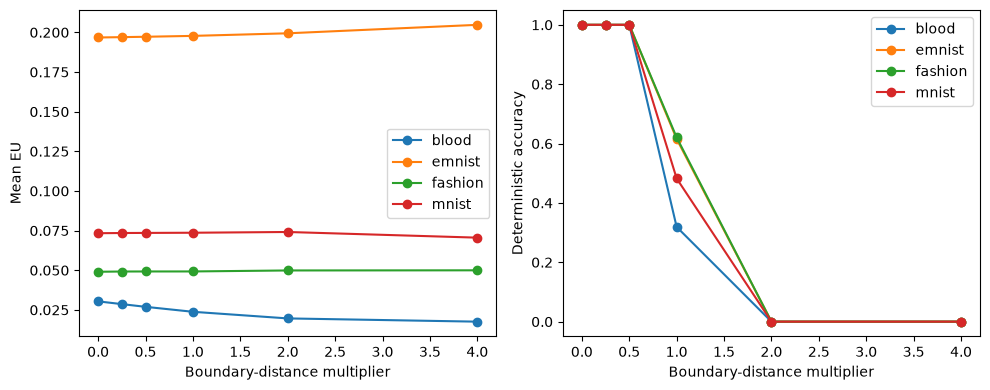

In [11]:
linear_rows = []
for name, w in worlds.items():
    torch.manual_seed(w['seed']+600)
    linear = nn.Sequential(nn.Dropout(.5), nn.Linear(64, w['K']+1))
    fit(linear, w['train']['X'], w['train_y'], HEAD_EPOCHS, w['seed']+600)
    w['linear'] = linear
    ids = np.flatnonzero(w['test']['roles'] == 'kkc')
    ids = np.random.default_rng(w['seed']).permutation(ids)[:ATTACK_ROWS]
    x = w['test']['X'][ids]
    y = mapped_labels(w, w['test']['labels'][ids])
    with torch.no_grad():
        correct = linear(x).argmax(1) == y
    x, y = x[correct], y[correct]
    if not len(x):
        print(name, ': no correct KKC rows for boundary analysis'); continue
    with torch.no_grad():
        z = linear(x)
        W = linear[1].weight
        dy = W[y, None, :]-W[None, :, :]
        norm = dy.norm(dim=2)
        margins = z.gather(1, y[:, None])-z
        distances = margins/norm.clamp_min(1e-12)
        distances[norm < 1e-12] = torch.inf
        distances[torch.arange(len(x)), y] = torch.inf
        distance, competitor = distances.min(dim=1)
        assert torch.isfinite(distance).all()
        direction = -nn.functional.normalize(dy[torch.arange(len(x)), competitor], dim=1)
        pair_before = margins[torch.arange(len(x)), competitor]
        pair_norm = norm[torch.arange(len(x)), competitor]
    for multiplier in [0., .25, .5, 1., 2., 4.]:
        adv = x+multiplier*distance[:, None]*direction
        with torch.no_grad():
            za = linear(adv)
            pair_after = za.gather(1, y[:, None]).squeeze(1)-za.gather(1, competitor[:, None]).squeeze(1)
            residual = (pair_after-pair_before+multiplier*distance*pair_norm).abs().max().item()
        assert residual < 1e-4, (name, residual)
        sc = score(linear, adv, w['K'], w['seed']+601)
        linear_rows.append(dict(dataset=name, n=len(x), multiplier=multiplier,
            displacement=float((adv-x).norm(dim=1).mean()), accuracy=(za.argmax(1) == y).float().mean().item(),
            TU=sc.tu.mean(), EU=sc.eu.mean(), pair_closure_max_error=residual))
linear_depth = pd.DataFrame(linear_rows)
display(linear_depth.round(5))
if not linear_depth.empty:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for name, sub in linear_depth.groupby('dataset'):
        axes[0].plot(sub.multiplier, sub.EU, 'o-', label=name)
        axes[1].plot(sub.multiplier, sub.accuracy, 'o-', label=name)
    axes[0].set(xlabel='Boundary-distance multiplier', ylabel='Mean EU')
    axes[1].set(xlabel='Boundary-distance multiplier', ylabel='Deterministic accuracy')
    axes[0].legend(); axes[1].legend(); plt.tight_layout(); plt.show()

## 11. Training duration: early vs final head

Fit a separate 5-epoch MLP from the same initialization and shuffle seed as the final model. Compare KKC accuracy and UUC detection. Low disagreement can reflect confidence saturation, so detection scores should be read alongside classification accuracy. The encoder stays fixed. This is a duration diagnostic, not a search for the best epoch on the test set.

In [12]:
duration_rows = []
for name, w in worlds.items():
    torch.manual_seed(w['seed']+100)
    early = HeadDrop(w['K'])
    fit(early, w['train']['X'], w['train_y'], 5, w['seed']+100)
    selected = np.isin(w['test']['roles'], ['kkc', 'uuc_test'])
    target = w['test']['roles'][selected] == 'uuc_test'
    for tag, model in [('5 epochs', early), (f'{HEAD_EPOCHS} epochs', w['head'])]:
        sc = score(model, w['test']['X'][selected], w['K'], w['seed']+700)
        truth = mapped_labels(w, w['test']['labels'][selected]).numpy()
        duration_rows.append(dict(dataset=name, model=tag,
            known_accuracy=(sc.prediction.to_numpy()[~target] == truth[~target]).mean(),
            **{s+'_auroc': roc_auc_score(target, sc[s]) for s in ['eu', 'tu', 'p_unknown', 'neg_margin']}))
duration = pd.DataFrame(duration_rows)
display(duration.round(4))

,dataset,model,known_accuracy,eu_auroc,tu_auroc,p_unknown_auroc,neg_margin_auroc
0,mnist,5 epochs,0.8738,0.2571,0.8404,0.7352,0.7933
1,mnist,100 epochs,0.8862,0.8197,0.8621,0.8462,0.7909
2,emnist,5 epochs,0.0800,0.4462,0.6250,0.6076,0.3148
3,emnist,100 epochs,0.7481,0.6156,0.6381,0.7863,0.5917
4,fashion,5 epochs,0.8788,0.4049,0.5317,0.6076,0.6792
5,fashion,100 epochs,0.8925,0.6975,0.7313,0.6815,0.7090
6,blood,5 epochs,0.5217,0.7529,0.2136,0.2609,0.2425
7,blood,100 epochs,0.8133,0.3749,0.2647,0.2624,0.2642


## 12. Optional bootstrap ensemble

Set `RUN_BOOTSTRAP_ENSEMBLE=True` in the configuration cell and rerun this cell to compare data-resampling disagreement with dropout disagreement. Each member resamples head-training rows and has an independent initialization. Predictions here are deterministic per member; ensemble EU is entropy of the mean minus mean member entropy. The encoder remains fixed, so this omits encoder uncertainty.

Unlike dropout EU given TU and AU, this ensemble statistic is a different source of disagreement. Its value must still be assessed empirically; no superiority claim is built in.

In [13]:
ensemble_rows = []
if RUN_BOOTSTRAP_ENSEMBLE:
    assert ENSEMBLE_MEMBERS >= 2
    for name, w in worlds.items():
        rng = np.random.default_rng(w['seed']+800)
        selected = np.isin(w['test']['roles'], ['kkc', 'uuc_test'])
        x = w['test']['X'][selected]
        target = w['test']['roles'][selected] == 'uuc_test'
        members = []
        for m in range(ENSEMBLE_MEMBERS):
            seed = w['seed']+801+m
            torch.manual_seed(seed)
            model = HeadDrop(w['K'])
            ids = rng.integers(len(w['train_y']), size=len(w['train_y']))
            fit(model, w['train']['X'][ids], w['train_y'][ids], HEAD_EPOCHS, seed)
            with torch.no_grad():
                members.append(model(x).softmax(-1).numpy())
        tu, au, eu = decompose(np.stack(members))
        ensemble_rows.append(dict(dataset=name, members=ENSEMBLE_MEMBERS,
                                  ensemble_EU_auroc=roc_auc_score(target, eu),
                                  ensemble_TU_auroc=roc_auc_score(target, tu)))
    display(pd.DataFrame(ensemble_rows).round(4))
else:
    print('Optional bootstrap ensemble skipped; set RUN_BOOTSTRAP_ENSEMBLE=True to run.')

Optional bootstrap ensemble skipped; set RUN_BOOTSTRAP_ENSEMBLE=True to run.


## 13. Optional export

Saving is off by default. A fresh output directory prevents accidental replacement of earlier runs. Save configuration, exact image/class assignments, per-image scores, diagnostics, and encoder/head weights together. Notebook output itself is saved by Jupyter.

In [14]:
SAVE_RESULTS = False
OUTPUT = ROOT / f'workbook/eu_blindspot_within_datasets_seed{SEED}'
if SAVE_RESULTS:
    OUTPUT.mkdir(parents=True, exist_ok=False)
    config = dict(seed=SEED, datasets=DATASETS, class_counts=CLASS_COUNTS,
        train_per_class=TRAIN_PER_CLASS, val_per_class=VAL_PER_CLASS, test_per_class=TEST_PER_CLASS,
        encoder_epochs=ENCODER_EPOCHS, head_epochs=HEAD_EPOCHS, mc_passes=MC_PASSES,
        batch_size=BATCH_SIZE, bootstrap_draws=BOOTSTRAP_DRAWS, attack_rows=ATTACK_ROWS,
        bootstrap_ensemble=RUN_BOOTSTRAP_ENSEMBLE, ensemble_members=ENSEMBLE_MEMBERS,
        torch_version=str(torch.__version__), feature_normalization='unit L2',
        fashion_protocol='official test pool repartitioned 60/20/20, not benchmark evaluation')
    (OUTPUT / 'config.json').write_text(json.dumps(config, indent=2))
    for title, table in [('assignments', assignments), ('class_roles', class_roles), ('scores', results),
                         ('calibration', calibration), ('detection', detection), ('per_class_detection', per_class_detection),
                         ('attacks', attacks), ('linear_depth', linear_depth), ('duration', duration)]:
        table.to_csv(OUTPUT / f'{title}.csv', index=False)
    summary.to_csv(OUTPUT / 'summary.csv')
    pd.DataFrame(ensemble_rows).to_csv(OUTPUT / 'ensemble.csv', index=False)
    for name, w in worlds.items():
        torch.save(dict(encoder=w['encoder'].state_dict(), head=w['head'].state_dict(),
                        linear=w['linear'].state_dict()), OUTPUT / f'{name}_models.pt')
    print('Saved to', OUTPUT)

## 14. Did we capture the original blind spot?

The original notebook calls **low TU / high EU** its “blind-spot quadrant.” We compute exactly that conjunction here as `warning`, using validation-KKC cutoffs instead of test-KKC cutoffs. Thus the quantity was measured above, but the previous ending did not answer the original question explicitly.

The table below separates three outcomes on never-seen **test UUC**:

- **Original quadrant:** low TU and high EU, regardless of prediction. This is the original operational definition.
- **Confident known-class error with an EU warning:** original-quadrant rows that predict a known class. These demonstrate confidence missing an error that elevated EU flags.
- **Silent missed warning:** low TU and low EU, predicting a known class. Both confidence and this EU cutoff miss the unknown example.

A confident prediction of the unknown output is successful rejection, not a known-class error. The original quadrant alone therefore cannot establish that the model was confidently wrong or unsupported. Likewise, two 90th-percentile cutoffs do **not** make their intersection 10% by construction.

All percentages below use all test-UUC rows as the denominator, except **EU warning coverage**, which conditions on confident known-class errors. These are observed cases for this fitted seed and split, not a general proof that EU detects unknowns.

In [15]:
verdict_rows = []
for name, w in worlds.items():
    frame = w['test_scores']
    known = frame[frame.role == 'kkc']
    unseen = frame[frame.role == 'uuc_test']
    original = unseen.warning
    flagged_errors = original & unseen.predicted_known
    silent_errors = unseen.low_tu_low_eu_known
    confident_errors = (unseen.tu <= w['q_tu']) & unseen.predicted_known
    # The two EU sides partition confident known-class errors on UUC.
    assert int(flagged_errors.sum() + silent_errors.sum()) == int(confident_errors.sum())
    verdict_rows.append(dict(
        dataset=name, known_test_accuracy=known.task_correct.mean(), n_UUC=len(unseen),
        original_quadrant_n=int(original.sum()), original_quadrant_pct=100*original.mean(),
        EU_flagged_known_errors_n=int(flagged_errors.sum()),
        EU_flagged_known_errors_pct=100*flagged_errors.mean(),
        silent_known_errors_n=int(silent_errors.sum()), silent_known_errors_pct=100*silent_errors.mean(),
        EU_warning_coverage_pct=(100*flagged_errors.sum()/confident_errors.sum()
                                 if confident_errors.any() else np.nan)))
blindspot_verdict = pd.DataFrame(verdict_rows).set_index('dataset')
with pd.option_context('display.max_columns', None):
    display(blindspot_verdict.round(2))
for name, row in blindspot_verdict.iterrows():
    print(f"{name}: original quadrant observed = {row.original_quadrant_n > 0}; "
          f"confident known-class errors flagged by EU = {int(row.EU_flagged_known_errors_n)}; "
          f"confident known-class errors missed by EU = {int(row.silent_known_errors_n)}.")


,known_test_accuracy,n_UUC,original_quadrant_n,original_quadrant_pct,EU_flagged_known_errors_n,EU_flagged_known_errors_pct,silent_known_errors_n,silent_known_errors_pct,EU_warning_coverage_pct
dataset,,,,,,,,,
mnist,0.89,800,31,3.88,23,2.88,151,18.88,13.22
emnist,0.76,1400,71,5.07,44,3.14,469,33.50,8.58
fashion,0.89,800,68,8.50,68,8.50,477,59.62,12.48
blood,0.81,600,46,7.67,45,7.50,461,76.83,8.89


mnist: original quadrant observed = True; confident known-class errors flagged by EU = 23; confident known-class errors missed by EU = 151.
emnist: original quadrant observed = True; confident known-class errors flagged by EU = 44; confident known-class errors missed by EU = 469.
fashion: original quadrant observed = True; confident known-class errors flagged by EU = 68; confident known-class errors missed by EU = 477.
blood: original quadrant observed = True; confident known-class errors flagged by EU = 45; confident known-class errors missed by EU = 461.


### What this does and does not establish

**Did the original quadrant occur?** Read `original_quadrant_n`. **Did EU flag errors that confidence missed?** Read `EU_flagged_known_errors_n` and `EU_warning_coverage_pct`. **Did EU itself have a blind spot?** Read `silent_known_errors_n`. All three can coexist in the same run.

This does not settle the original notebook's stronger claim that EU adds predictive value beyond entropy/margin baselines. We report detection comparisons, but do not reproduce its full CV/ETF hypothesis battery or establish an EU advantage. Dropout EU is TU−AU exactly. The optional bootstrap ensemble measures a different disagreement source, conditional on the frozen encoder.

Read these findings alongside known-class accuracy. Repeat class splits and fitting seeds before generalizing. Fashion uses a repartitioned cached test pool, not an official benchmark evaluation. Feature attacks need not be realizable images. AU and EU remain model-based entropy/disagreement proxies, not certificates of support or ground-truth noise.